# **Projet de Machine Learning - Sujet 1**
## CARLIER BARNOUX Léo

## **Introduction**
#### **Contexte :**
Ce projet vise à mettre en place un système de maintenance prédictive pour les machines de l'usine et à analyser les causes qui font que la condition de la valve d'un cycle de production est non optimale parfois.

#### **Objectif :**
Construire un modèle ML pour prédire si la condition valve est optimale (=100%) ou non, pour chaque cycle. Vous utiliserez les 2000 premiers cycles pour construire le modèle et le reste comme échantillon de test final.

#### **Données :**
Les données sont disponibles dans [[lien](https://drive.google.com/drive/folders/1YuqbS2c161SRiKJTSQODc1q3UOPFmVLX)]. Les données sont décrites dans [[lien](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)] à utiliser uniquement les 3 fichiers suivants, chaque ligne représentant un cycle :
- PS2 (Pression (bar) échantillonnage 100Hz)
- FS1 (Volume flow (l/min) échantillonnage 10Hz)
- Profile : Fichier avec les variables dont la "valve condition" qui nous intéresse.


## **Réalisation**

### **1. Prétraitement des données**
- Chargement des données et statistiques descriptives. 
-  Gestion des valeurs manquantes et détection des valeurs aberrantes. 
-  Encodage correct des variables catégorielles (si présentes). 
-  Transformation du problème en classification binaire. 
-  Analyse de la distribution des classes pour vérifier l’équilibre du jeu de données. 
-  Analyse des corrélations entre les variables. 
-  Visualisations (matrice de corrélation, histogrammes, boxplots). 
-  Utilisation de méthodes de sélection de variables (Features selection).

#### Chargement des données et statistiques descriptives

In [84]:
##Importation des librairies
import numpy as np
np.set_printoptions(suppress=True)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Librairies importées !")

Librairies importées !


In [85]:
##Chargement des données
df_profile = pd.read_csv("data/profile.txt", sep = "	", header=None) #profile
df_FS1 = pd.read_csv("data/FS1.txt", sep = "	", header=None) #FS1
df_PS2 = pd.read_csv("data/PS2.txt", sep = "	", header=None) #PS2

print("Les données sont chargées avec succès dans df_profile/df_FS1/df_PS2")

Les données sont chargées avec succès dans df_profile/df_FS1/df_PS2


In [86]:
##Affichage test des données
print("Profile :\n", df_profile.describe(), "\n")
print("FS1: \n", df_FS1.describe(), "\n")
print("PS2: \n", df_PS2.describe(), "\n")




Profile :
                  0            1            2            3            4
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000
mean     41.240816    90.693878     0.669388   107.199546     0.342857
std      42.383143    10.681802     0.817233    16.435848     0.474772
min       3.000000    73.000000     0.000000    90.000000     0.000000
25%       3.000000    80.000000     0.000000    90.000000     0.000000
50%      20.000000   100.000000     0.000000   100.000000     0.000000
75%     100.000000   100.000000     1.000000   130.000000     1.000000
max     100.000000   100.000000     2.000000   130.000000     1.000000 

FS1: 
                0            1            2            3            4    \
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000   
mean      8.287100     0.857298     0.563584     0.031154     0.003567   
std       0.480969     0.125100     0.152903     0.039403     0.002810   
min       7.033000     0.522000     0.309000 

In [87]:
print(df_FS1.head(3))
"""
FS1 est un capteur de débit en L/min et avec une fréquence de 10 Hz, on a 600 mesures par cycle
"""

     0      1      2      3      4      5      6      7      8      9    ...  \
0  8.990  0.770  0.641  0.006  0.000  0.000  0.001  0.003  0.001  0.001  ...   
1  8.919  0.815  0.709  0.009  0.004  0.000  0.001  0.000  0.000  0.001  ...   
2  9.179  0.683  0.528  0.008  0.003  0.001  0.003  0.003  0.004  0.006  ...   

     590    591    592    593    594    595    596    597    598    599  
0  7.743  7.992  7.919  7.773  7.955  7.823  7.963  7.876  7.738  8.036  
1  7.831  8.003  7.923  7.745  7.867  7.747  7.969  7.969  7.963  7.890  
2  7.862  7.815  7.894  7.743  7.936  7.770  7.982  7.873  7.898  7.952  

[3 rows x 600 columns]


'\nFS1 est un capteur de débit en L/min et avec une fréquence de 10 Hz, on a 600 mesures par cycle\n'

In [88]:
print(df_PS2.head(3))
"""
PS2 est un capteur de pression en bar et avec une pression de 100 Hz,
 on obtient 6000 mesures par cycles
"""

     0       1       2       3       4       5       6       7       8     \
0  125.50  125.39  125.40  125.03  124.05  123.18  104.01  56.500  23.992   
1  125.06  125.08  125.09  124.69  123.84  123.14  103.63  63.687  28.359   
2  125.13  125.27  125.23  124.74  123.94  123.23  106.35  60.516  26.258   

     9     ...    5990    5991    5992    5993    5994    5995    5996  \
0  18.406  ...  125.02  125.00  125.10  125.09  124.98  124.91  124.98   
1  21.711  ...  124.80  124.88  125.13  125.22  125.09  124.98  125.06   
2  19.258  ...  124.61  124.69  124.74  124.71  124.59  124.64  124.74   

     5997    5998    5999  
0  125.11  125.14  125.10  
1  125.13  125.09  125.04  
2  124.73  124.77  124.88  

[3 rows x 6000 columns]


'\nPS2 est un capteur de pression en bar et avec une pression de 100 Hz,\n on obtient 6000 mesures par cycles\n'

In [89]:
df_profile.rename(columns={0: "Cooler"}, inplace=True)
df_profile.rename(columns={1: "Valve"}, inplace=True)
df_profile.rename(columns={2: "Pump"}, inplace=True)
df_profile.rename(columns={3: "Accumulator"}, inplace=True)
df_profile.rename(columns={4: "Stable flag"}, inplace=True)
print(df_profile.head(3))
"""
Profile contient les labels associés à chaque cycle soit les
 valeurs objectifs à observer pour chaque colonne :
- 
"""

   Cooler  Valve  Pump  Accumulator  Stable flag
0       3    100     0          130            1
1       3    100     0          130            1
2       3    100     0          130            1


'\nProfile contient les labels associés à chaque cycle soit les\n valeurs objectifs à observer pour chaque colonne :\n- \n'

### Analyse (première) :
On peut voir qu'on a énormément de variables/mesures (total de 6600 mesures par cycles pour seulement 2205 cycles), or une telle quantité de "dimensions" n'est pas vraiment adapter pour l'utilisation de modèle (c'est possible, mais très lourd et très sensible au bruit → overfitting).

On va donc calculer/selectionner d'autres "dimensions" plus globales dans nos mesures : la pression moyenne/max/min sur un cycle et la même chose pour le débit.

On pourra alors entraîner les modèles sur ces caractéristiques moins nombreuses et permettant de comprendre les variations plus générales (**motifs**) du comportement des valves.

Cette réduction de dimension est différente d'une ACP (PCA), car les nouvelles caractéristiques sont construites manuellement à partir de connaissances métier et restent interprétables physiquement.



#### Features engineering (analyse et choix attributs)

In [90]:
#Création des nouvelles dimensions et stockage dans un dataframe
x_dimensions = pd.DataFrame()

#FS1
x_dimensions["FS1_moyenne"] = df_FS1.mean(axis=1)
x_dimensions["FS1_ecart_type"] = df_FS1.std(axis=1)
x_dimensions["FS1_min"] = df_FS1.min(axis=1)
x_dimensions["FS1_max"] = df_FS1.max(axis=1)
x_dimensions["FS1_median"] = df_FS1.median(axis=1)

#PS2
x_dimensions["PS2_mean"] = df_PS2.mean(axis=1)
x_dimensions["PS2_ecart_type"] = df_PS2.std(axis=1)
x_dimensions["PS2_min"] = df_PS2.min(axis=1)
x_dimensions["PS2_max"] = df_PS2.max(axis=1)
x_dimensions["PS2_median"] = df_PS2.median(axis=1)

print(x_dimensions.head())
print('\nDimension attributs :', x_dimensions.shape)

   FS1_moyenne  FS1_ecart_type  FS1_min  FS1_max  FS1_median    PS2_mean  \
0     6.709815        3.015428      0.0   18.710       7.836  109.466914   
1     6.715315        3.006248      0.0   18.712       7.853  109.354890   
2     6.718522        3.014248      0.0   18.698       7.847  109.158845   
3     6.720565        3.020176      0.0   18.896       7.843  109.064807   
4     6.690308        3.011550      0.0   18.876       7.831  108.931434   

   PS2_ecart_type  PS2_min  PS2_max  PS2_median  
0       47.114508      0.0   156.99     129.365  
1       47.045611      0.0   157.56     129.385  
2       46.992060      0.0   156.97     129.325  
3       46.972221      0.0   156.44     128.865  
4       46.874946      0.0   158.13     129.000  

Dimension attributs : (2205, 10)


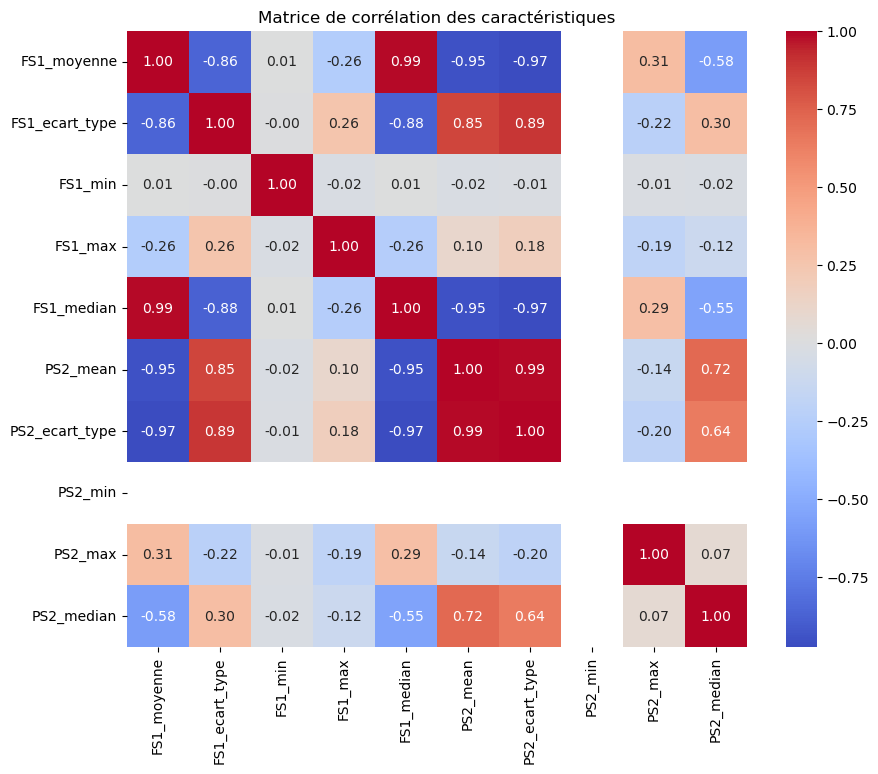

In [91]:
#Matrice de corrélation
plt.figure(figsize=(10,8))

sns.heatmap(
    x_dimensions.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation des caractéristiques")
plt.show()


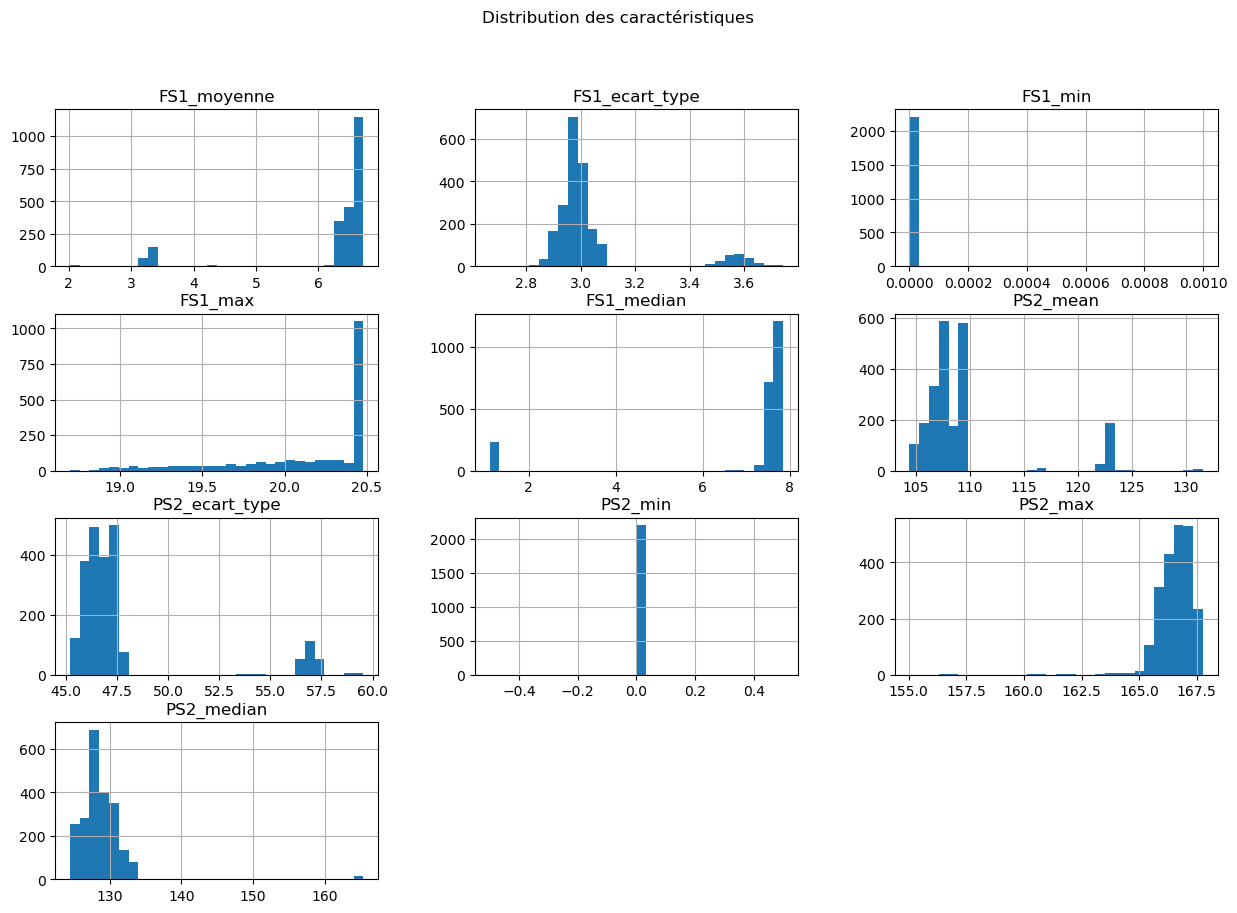

In [92]:
#Histogrammes
x_dimensions.hist(figsize=(15,10),bins=30)
plt.suptitle("Distribution des caractéristiques")
plt.show()


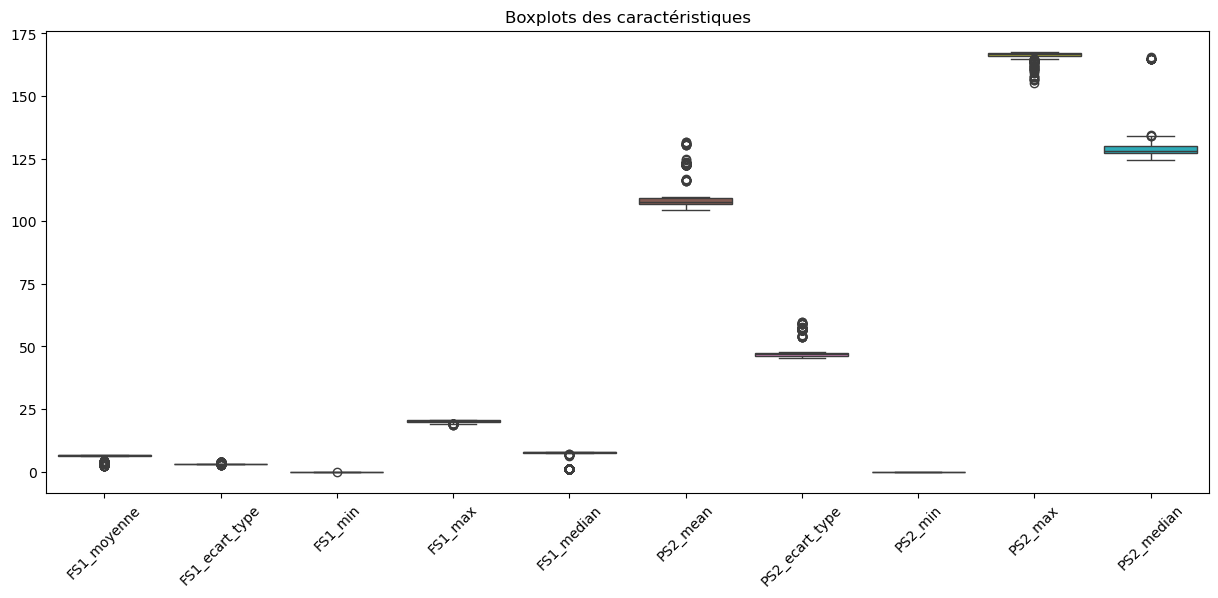

In [93]:
#Boxplots
plt.figure(figsize=(15,6))
sns.boxplot(data=x_dimensions)

plt.xticks(rotation=45)
plt.title("Boxplots des caractéristiques")
plt.show()

In [94]:
x_dimensions["PS2_min"].describe()
x_dimensions["FS1_min"].describe()

count    2.205000e+03
mean     4.535147e-07
std      2.129589e-05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e-03
Name: FS1_min, dtype: float64

**Matrice corrélation :**
On remarque que PS2_min et FS1_min donnent toujours 0, ce qui est possible puisque sur un cycle le flux et le débit peuvent être nuls à un moment donné.
En regardant de plus près on voit que PS2_min est toujours nul pour chaque cycle et n'est donc pas intéressant à traiter.

Aussi, F1_median et F1_moyenne sont extrêmement corrélé et donc similaires, de même pour PS2_mean et PS2_ecart_type; FS1_moyenne et PS2_mean; FS1_median et PS2_mean.
La simularité entre ces variables sera à prendre en compte dans la suite pour éviter certaines incohérences.

**Histogrammes :**
De ce côté, on voit bien plusieurs regroupement de valeurs différentes pour certaines mesures, ces regroupement permettront peut-être de déterminer la classe de la valve.


**Boxplots :**
On remarque ici plusieurs valeurs extrêmes, mais ces dernières peuvent correspondre à des conditions de fonctionnement particulières du système hydraulique plutôt qu'à des erreurs de mesure.


#### Feature Selection (choix des mesures intéressantes/utiles)

On va supprimer seulement PS2_min et garder les autres pour garder le maximum d'informations.

In [95]:
#Suppresion PS2_min
X_dimensions = x_dimensions.drop(columns=["PS2_min"])

#### Création de la cible binaire

In [96]:
#Mise en place
y = (df_profile["Valve"] == 100).astype(int)

#Test
print(y.value_counts())

Valve
1    1125
0    1080
Name: count, dtype: int64


#### Séparation des données (train - test)

In [97]:
#Création des tableaux
X_train = X_dimensions.iloc[:2000]
X_test  = X_dimensions.iloc[2000:]

y_train = y.iloc[:2000]
y_test  = y.iloc[2000:]

In [98]:
#Test
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(2000, 9)
(205, 9)
(2000,)
(205,)


### **2. Modélisation et Évaluation**
- Modèles envisagés : régression logistique, k-NN, arbre de décision, Naive Bayes, 
SVM, ensemble learning.  
- Justification du choix des modèles selon :  
    - Leurs propriétés théoriques (linéaires vs non linéaires).
    - Leur adaptabilité au type de données (distributions continues, bruit, etc.). 

##### Choix des modèles
Plusieurs modèles différents peuvent convenir pour ce projet, j'en ai retenu quelques-uns qui serviront pour certains de baseline, de tests et d'autres à pousser l'apprentissage des modèles plus loin :

**Régression logistique**
La régression logistique est un modèle linéaire souvent utilisé comme référence en classification binaire. Elle cherche une frontière de décision linéaire entre les classes. Sa simplicité permet d'obtenir un premier point de comparaison et de mesurer dans quelle mesure le problème est linéairement séparable.

**KNN - k-Nearest Neighbors**
Le modèle k-NN est un algorithme non paramétrique basé sur la proximité des observations dans l'espace des caractéristiques. Il est particulièrement adapté lorsque des cycles présentant des caractéristiques similaires ont tendance à appartenir à la même classe.


**Arbre de Décision**
Les arbres de décision sont capables de construire des règles de décision non linéaires et facilement interprétables. Ils permettent de capturer des interactions complexes entre les mesures de débit et de pression.

**Naive Bayes**
Naive Bayes repose sur une approche probabiliste et suppose une indépendance conditionnelle entre les variables. Malgré cette hypothèse forte, il constitue souvent une bonne référence grâce à sa rapidité d'entraînement et sa robustesse.

**Support Vector Machine (SVM)**
Les SVM recherchent une frontière de séparation maximisant la marge entre les classes. Grâce à l'utilisation de noyaux, ils peuvent modéliser des relations aussi bien linéaires que non linéaires et sont souvent performants sur des jeux de données de taille moyenne.

**Ensemble Learning (Random Forest)**
Les méthodes d'ensemble combinent plusieurs modèles afin d'améliorer les performances et la robustesse. Dans ce projet, une Random Forest sera utilisée. Elle réduit généralement le risque de surapprentissage présent dans un arbre de décision unique tout en fournissant une estimation de l'importance des variables.



##### Adaptation au problème étudié
Les caractéristiques construites à partir des mesures de pression (PS2) et de débit (FS1) sont des variables numériques continues. Les modèles retenus sont donc tous capables d'exploiter efficacement ce type de données.
L'utilisation conjointe de modèles linéaires (régression logistique), non linéaires (arbres de décision, SVM à noyau, k-NN) et d'ensemble (Random Forest) permettra d'identifier l'approche la mieux adaptée à la prédiction de la condition de la valve.



### **3. Évaluation des modèles**
- Évaluation des modèles à l’aide de métriques pertinentes :  
    - Accuracy, précision, rappel, F1-score. 
    - Matrice de confusion. 
    - Courbe ROC et AUC.  
- Comparaison des performances et interprétation des résultats.  
- Identification du modèle le plus performant selon un compromis biais/variance.  

##### Préparation + Implémentation

In [99]:
#Normalisation des données - nécessaire pour KNN, SVM...
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

#On vérifie si perte de donnée
print(X_train_norm.shape)
print(X_test_norm.shape)

(2000, 9)
(205, 9)


Pour me faciliter l'évaluation des différents modèles, j'ai construit une fonction d'évaluation.

Elle fait tourner le modèle sur les données d'entraînement et de test et donne les statistiques de son résultat. On utilisera ces statistiques pour déterminer le meilleur modèle.

In [100]:
#Importation des métriques pour les statistiques d'évaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [101]:
#Implémentation de la fonction d'évaluation
def evaluer_model(model, Xtrain, Ytrain, Xtest, Ytest):
    model.fit(Xtrain, Ytrain)
    y_pred = model.predict(Xtest)

    acc = accuracy_score(Ytest, y_pred)
    rec = recall_score(Ytest, y_pred)
    moy = (acc + rec) / 2

    print(confusion_matrix(Ytest, y_pred))
    print(classification_report(Ytest, y_pred))

    print(f"Accuracy : {acc:.5f}")
    print(f"Recall   : {rec:.5f}")
    print(f"Moyenne  : {moy:.5f}")

    return acc, rec, moy

In [102]:
#Dictionnaire des résultats
resultats = {}

##### Évaluation des modèles

###### **Régression Logistique (baseline)**

In [103]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=42)

print("===== Logistic Regression =====")

resultats["Logistic Regression"] = evaluer_model(
    lr,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== Logistic Regression =====
[[82 50]
 [ 0 73]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.77       132
           1       0.59      1.00      0.74        73

    accuracy                           0.76       205
   macro avg       0.80      0.81      0.76       205
weighted avg       0.86      0.76      0.76       205

Accuracy : 0.75610
Recall   : 1.00000
Moyenne  : 0.87805


###### **Naive Bayes**

In [104]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()

print("===== Naive Bayes =====")

resultats["Naive Bayes"] = evaluer_model(
    gnb,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== Naive Bayes =====
[[  0 132]
 [  0  73]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       132
           1       0.36      1.00      0.53        73

    accuracy                           0.36       205
   macro avg       0.18      0.50      0.26       205
weighted avg       0.13      0.36      0.19       205

Accuracy : 0.35610
Recall   : 1.00000
Moyenne  : 0.67805


c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


###### **Arbre de Décision**

In [105]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(criterion="entropy", random_state=99)

print("===== Decision Tree =====")
resultats["Decision Tree"] = evaluer_model(
    dt,
    X_train,
    y_train,
    X_test,
    y_test
)

===== Decision Tree =====
[[100  32]
 [  0  73]]
              precision    recall  f1-score   support

           0       1.00      0.76      0.86       132
           1       0.70      1.00      0.82        73

    accuracy                           0.84       205
   macro avg       0.85      0.88      0.84       205
weighted avg       0.89      0.84      0.85       205

Accuracy : 0.84390
Recall   : 1.00000
Moyenne  : 0.92195


###### **Random Forest (Ensemble learninf)**

In [106]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=79)
print("===== Random Forest =====")

resultats["Random Forest"] = evaluer_model(
    rf,
    X_train,
    y_train,
    X_test,
    y_test
)

===== Random Forest =====
[[103  29]
 [  0  73]]
              precision    recall  f1-score   support

           0       1.00      0.78      0.88       132
           1       0.72      1.00      0.83        73

    accuracy                           0.86       205
   macro avg       0.86      0.89      0.86       205
weighted avg       0.90      0.86      0.86       205

Accuracy : 0.85854
Recall   : 1.00000
Moyenne  : 0.92927


###### **KNN (k=5 et k=3)**

In [107]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

print("===== KNN (k=5) =====")

resultats["KNN_5"] = evaluer_model(
    knn,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== KNN (k=5) =====
[[90 42]
 [ 5 68]]
              precision    recall  f1-score   support

           0       0.95      0.68      0.79       132
           1       0.62      0.93      0.74        73

    accuracy                           0.77       205
   macro avg       0.78      0.81      0.77       205
weighted avg       0.83      0.77      0.78       205

Accuracy : 0.77073
Recall   : 0.93151
Moyenne  : 0.85112


In [108]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)

print("===== KNN (k=3) =====")

resultats["KNN_3"] = evaluer_model(
    knn,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== KNN (k=3) =====
[[94 38]
 [ 2 71]]
              precision    recall  f1-score   support

           0       0.98      0.71      0.82       132
           1       0.65      0.97      0.78        73

    accuracy                           0.80       205
   macro avg       0.82      0.84      0.80       205
weighted avg       0.86      0.80      0.81       205

Accuracy : 0.80488
Recall   : 0.97260
Moyenne  : 0.88874


###### **SVM Linéaire**

In [109]:
from sklearn.svm import SVC
svm_linear = SVC(kernel="linear", random_state=58)
print("===== SVM Linear =====")

resultats["SVM Linear"] = evaluer_model(
    svm_linear,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== SVM Linear =====
[[82 50]
 [ 0 73]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.77       132
           1       0.59      1.00      0.74        73

    accuracy                           0.76       205
   macro avg       0.80      0.81      0.76       205
weighted avg       0.86      0.76      0.76       205

Accuracy : 0.75610
Recall   : 1.00000
Moyenne  : 0.87805


###### SVM RBF

In [110]:
svm_rbf = SVC(kernel="rbf", random_state=21)
print("===== SVM RBF =====")

resultats["SVM RBF"] = evaluer_model(
    svm_rbf,
    X_train_norm,
    y_train,
    X_test_norm,
    y_test
)

===== SVM RBF =====
[[97 35]
 [ 0 73]]
              precision    recall  f1-score   support

           0       1.00      0.73      0.85       132
           1       0.68      1.00      0.81        73

    accuracy                           0.83       205
   macro avg       0.84      0.87      0.83       205
weighted avg       0.88      0.83      0.83       205

Accuracy : 0.82927
Recall   : 1.00000
Moyenne  : 0.91463


##### COmparaison des résultats
Pour cela, on utilisera un dataframe "comparaison".

In [111]:
comparaison = pd.DataFrame(resultats,index=["Accuracy", "Recall", "Moyenne"]).T

comparaison = comparaison.sort_values(
    by="Moyenne",
    ascending=False
)

#print(comparaison)
comparaison

,Accuracy,Recall,Moyenne
Random Forest,0.858537,1.000000,0.929268
Decision Tree,0.843902,1.000000,0.921951
SVM RBF,0.829268,1.000000,0.914634
KNN_3,0.804878,0.972603,0.888740
Logistic Regression,0.756098,1.000000,0.878049
SVM Linear,0.756098,1.000000,0.878049
KNN_5,0.770732,0.931507,0.851119
Naive Bayes,0.356098,1.000000,0.678049


#### Analyse des résultats

**1. Recall = 1.0** :
Pour tous les modèles sauf KNN (k=3 et k=5), le recall est égale à 1, cela signifie que tous les cycles de valve optimale ont été détectés. Ces modèles trouvent donc toujours les valves optimales.

**2. Moyennes/résultats proches**
Random Forest, Decistion Tree et SVM RBF ont des performances très similaires (respectivement 0.929, 0.922, 0.915) et hauts. Les résultats sont satisfaisant pour ces modèles.

**3. Égalité Logistic Regression et SVM linear**
Les deux modèles ont des résultats identiques et on peut donc en déduire que la classification par linéarité est déjà partiellement correcte (les deux doivent utiliser la même droite) avec quelques relations non linéaires entre les données.

**4. Échec de Naives Bayes**
Les résultats du modèle Naives Bayes sont bien moins bons que ceux des autres modèles. En cherchant au niveau de la Matrice de corrélation, on peut voir que certaines variables/dimensions sont très proches (fS1_moyenne et FS1_median par exemple). Or Naives Bayes a pour hypothèse de base la séparation complètes des dimensions des données, le non-respect de cette condition fait chuter l'accuracy.

#### Courbe ROC et AUC

In [112]:
#Implémentation d'une fonction d'affichage/comparaison de ROC
from sklearn.metrics import roc_curve, roc_auc_score

def afficher_roc(modeles, Xtest, ytest):
    plt.figure(figsize=(8,6))

    for nom, modele in modeles.items():
        y_proba = modele.predict_proba(Xtest)[:,1]

        fpr, tpr, _ = roc_curve(ytest, y_proba)
        auc = roc_auc_score(ytest,y_proba)

        plt.plot(fpr, tpr, label=f"{nom} (AUC={auc:.3f})")

    plt.plot([0,1],[0,1],'k--')

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Comparaison des courbes ROC")
    plt.legend()
    plt.grid(True)

    plt.show()


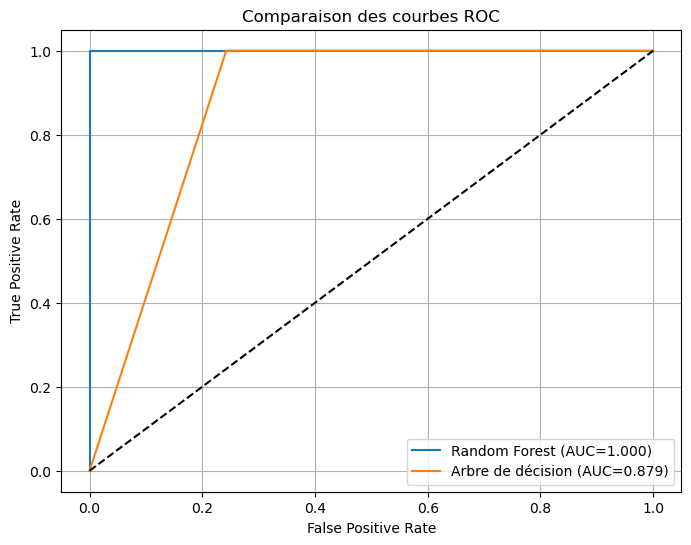

In [113]:
#Test avec Random Forest, Decision Tree et SVM RBF
afficher_roc({"Random Forest": rf,
              "Arbre de décision": dt
              }, X_test, y_test)

### **4. Optimisation des hyperparamètres**
- Utilisation de techniques d’optimisation telles que :  
    - Grid Search : recherche exhaustive sur une grille d’hyperparamètres.  
    - Random Search : recherche aléatoire pour un gain de temps.  
-  Évaluation des modèles optimisés via validation croisée (k-fold). 

In [114]:
#Pour les hyperparamètres, on peut utiliser les données de Random Forest
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance",ascending=False)

print(importance)

          Feature  Importance
1  FS1_ecart_type    0.208171
0     FS1_moyenne    0.200063
6  PS2_ecart_type    0.194834
5        PS2_mean    0.151747
4      FS1_median    0.132652
8      PS2_median    0.056362
3         FS1_max    0.031998
7         PS2_max    0.024173
2         FS1_min    0.000000


#### Analyse 2.1 :
On voit bien que FS1_min n'est pas important (du moins pour Random Forest), on peut donc le supprimer sans prendre trop de risque.
On verra plus tard pour FS1_mac, PS2_max et PS2_median qui ont eux aussi une très faible importance.

In [115]:
###Suppresion de FS1_min
X_dim = X_dimensions.drop(columns=["FS1_min"])

##On reforme X_train et X_test
X_train_fs = X_dim.iloc[:2000]
X_test_fs = X_dim.iloc[2000:]

#Normalisation
scaler_fs = StandardScaler()
X_train_fs_norm = scaler_fs.fit_transform(X_train_fs)
X_test_fs_norm = scaler_fs.transform(X_test_fs)

#On entraîne de nouveaux les modèles
modeles = {"Logistic Regression":
        (
        LogisticRegression(max_iter=800, random_state=38),
        X_train_fs_norm, X_test_fs_norm
        ),

    "Naive Bayes":
        (
            GaussianNB(),
            X_train_fs_norm, X_test_fs_norm
        ),

    "Decision Tree":
        (
            DecisionTreeClassifier(criterion="entropy", random_state=12),
            X_train_fs, X_test_fs
        ),

    "Random Forest":
        (
            RandomForestClassifier( n_estimators=100, random_state=56),
            X_train_fs,X_test_fs
        ),

    "KNN_3":
        (
            KNeighborsClassifier(n_neighbors=3),
            X_train_fs_norm, X_test_fs_norm
        ),

    "KNN_5":
        (
            KNeighborsClassifier(n_neighbors=5),
            X_train_fs_norm, X_test_fs_norm
        ),

    "SVM Linear":
        (
            SVC(kernel="linear"),
            X_train_fs_norm, X_test_fs_norm
        ),

    "SVM RBF":
        (
            SVC(kernel="rbf"),
            X_train_fs_norm, X_test_fs_norm
        )
}

In [116]:
resultats_fs = {}
for nom, (modele, Xtrain, Xtest) in modeles.items():
    print(f"\n{'='*20} {nom} {'='*20}")
    resultats_fs[nom] = evaluer_model(modele, Xtrain,y_train, Xtest, y_test)


==================== Logistic Regression ====================
[[82 50]
 [ 0 73]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.77       132
           1       0.59      1.00      0.74        73

    accuracy                           0.76       205
   macro avg       0.80      0.81      0.76       205
weighted avg       0.86      0.76      0.76       205

Accuracy : 0.75610
Recall   : 1.00000
Moyenne  : 0.87805

==================== Naive Bayes ====================
[[  0 132]
 [  0  73]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       132
           1       0.36      1.00      0.53        73

    accuracy                           0.36       205
   macro avg       0.18      0.50      0.26       205
weighted avg       0.13      0.36      0.19       205

Accuracy : 0.35610
Recall   : 1.00000
Moyenne  : 0.67805

==================== Decision Tree ====================
[[100  32]
 [  

c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\leoca\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


[[107  25]
 [  0  73]]
              precision    recall  f1-score   support

           0       1.00      0.81      0.90       132
           1       0.74      1.00      0.85        73

    accuracy                           0.88       205
   macro avg       0.87      0.91      0.87       205
weighted avg       0.91      0.88      0.88       205

Accuracy : 0.87805
Recall   : 1.00000
Moyenne  : 0.93902

==================== KNN_3 ====================
[[94 38]
 [ 2 71]]
              precision    recall  f1-score   support

           0       0.98      0.71      0.82       132
           1       0.65      0.97      0.78        73

    accuracy                           0.80       205
   macro avg       0.82      0.84      0.80       205
weighted avg       0.86      0.80      0.81       205

Accuracy : 0.80488
Recall   : 0.97260
Moyenne  : 0.88874

==================== KNN_5 ====================
[[90 42]
 [ 5 68]]
              precision    recall  f1-score   support

           0      

In [119]:
#Ancien résultats
comparaison

,Accuracy,Recall,Moyenne
Random Forest,0.858537,1.000000,0.929268
Decision Tree,0.843902,1.000000,0.921951
SVM RBF,0.829268,1.000000,0.914634
KNN_3,0.804878,0.972603,0.888740
Logistic Regression,0.756098,1.000000,0.878049
SVM Linear,0.756098,1.000000,0.878049
KNN_5,0.770732,0.931507,0.851119
Naive Bayes,0.356098,1.000000,0.678049


In [117]:
#Comparaison rapide avec/sans FS1
comparaison_fs = pd.DataFrame(resultats_fs,index=["Accuracy", "Recall", "Moyenne"]
                ).T.sort_values(by="Moyenne",ascending=False
)

comparaison_fs

,Accuracy,Recall,Moyenne
Random Forest,0.878049,1.000000,0.939024
Decision Tree,0.843902,1.000000,0.921951
SVM RBF,0.829268,1.000000,0.914634
KNN_3,0.804878,0.972603,0.888740
Logistic Regression,0.756098,1.000000,0.878049
SVM Linear,0.756098,1.000000,0.878049
KNN_5,0.770732,0.931507,0.851119
Naive Bayes,0.356098,1.000000,0.678049


On peut noter une petite amélioration de Random Forest, mais le reste des résultats est identique. Cela montre bien que F1_min n'était pas utile à l'entraînement des modèles

#### 4.1 Optimisation avec Grid Search
On va tester d'améliorer Random Forest avec GridSearchCV puisque c'est l'actuel meilleur modèle.

In [122]:
#Recherche des meilleurs hyperparamètres pour Random Forest
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid_reference = {"n_estimators" : [50, 100 ,200],
                        "max_depth": [None, 5, 10, 20],
                        "min_samples_split": [2, 5, 10]}

rf_grid = GridSearchCV(estimator=RandomForestClassifier(random_state=2005),
                        param_grid=param_grid_reference, cv=5,
                        scoring="accuracy", n_jobs=-1)

rf_grid.fit(X_train_fs, y_train)

print("Meilleurs paramètres RF:")
print(rf_grid.best_params_)
print("Meilleurs paramètres CV:")
print(rf_grid.best_score_)

Meilleurs paramètres RF:
{'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Meilleurs paramètres CV:
0.7945


In [125]:
#Test de ces hyperparamètres
best_rf = rf_grid.best_estimator_

resultats["Random Forest Opti"] = evaluer_model(
    best_rf,
    X_train_fs, y_train,
    X_test_fs, y_test
)

[[122  10]
 [  0  73]]
              precision    recall  f1-score   support

           0       1.00      0.92      0.96       132
           1       0.88      1.00      0.94        73

    accuracy                           0.95       205
   macro avg       0.94      0.96      0.95       205
weighted avg       0.96      0.95      0.95       205

Accuracy : 0.95122
Recall   : 1.00000
Moyenne  : 0.97561


#### 4.2 Optimisation avec SVC
On va tester d'améliorer SVM RBF avec SVC et voir si son optimisation lui permet de surpasser/rattraper Random Forest.

In [140]:
#Recherche des meilleurs hyperparamètres
from sklearn.svm import SVC

param_grid_svm = {"C": [0.1, 1, 10, 100],
                  "gamma": ["scale", 0.1, 0.01, 0.001]
}

svm_grid = GridSearchCV(estimator = SVC(kernel="rbf", probability=True),
                        param_grid=param_grid_svm,
                        cv = 5, scoring="accuracy",
                        n_jobs=-1)

svm_grid.fit(X_train_fs_norm, y_train)
print("Meilleurs paramètres SVM :")
print(svm_grid.best_params_)

print("Meilleur score CV :")
print(svm_grid.best_score_)

Meilleurs paramètres SVM :
{'C': 100, 'gamma': 0.01}
Meilleur score CV :
0.933


In [141]:
best_svm = svm_grid.best_estimator_

resultats["SVM RBF Optimisé"] = evaluer_model(
    best_svm,
    X_train_fs_norm, y_train,
    X_test_fs_norm, y_test
)

[[113  19]
 [  0  73]]
              precision    recall  f1-score   support

           0       1.00      0.86      0.92       132
           1       0.79      1.00      0.88        73

    accuracy                           0.91       205
   macro avg       0.90      0.93      0.90       205
weighted avg       0.93      0.91      0.91       205

Accuracy : 0.90732
Recall   : 1.00000
Moyenne  : 0.95366


In [142]:
#Comparaison avec les nouveaux résultats
comparaison_fs = pd.DataFrame(resultats,index=["Accuracy", "Recall", "Moyenne"]).T
comparaison_fs = comparaison_fs.sort_values(by="Moyenne",ascending=False)

#print(comparaison)
comparaison_fs

,Accuracy,Recall,Moyenne
Random Forest Opti,0.951220,1.000000,0.975610
SVM RBF Optimisé,0.907317,1.000000,0.953659
Random Forest,0.858537,1.000000,0.929268
Decision Tree,0.843902,1.000000,0.921951
SVM RBF,0.829268,1.000000,0.914634
KNN_3,0.804878,0.972603,0.888740
Logistic Regression,0.756098,1.000000,0.878049
SVM Linear,0.756098,1.000000,0.878049
KNN_5,0.770732,0.931507,0.851119
Naive Bayes,0.356098,1.000000,0.678049


In [143]:
print(best_svm)

SVC(C=100, gamma=0.01, probability=True)


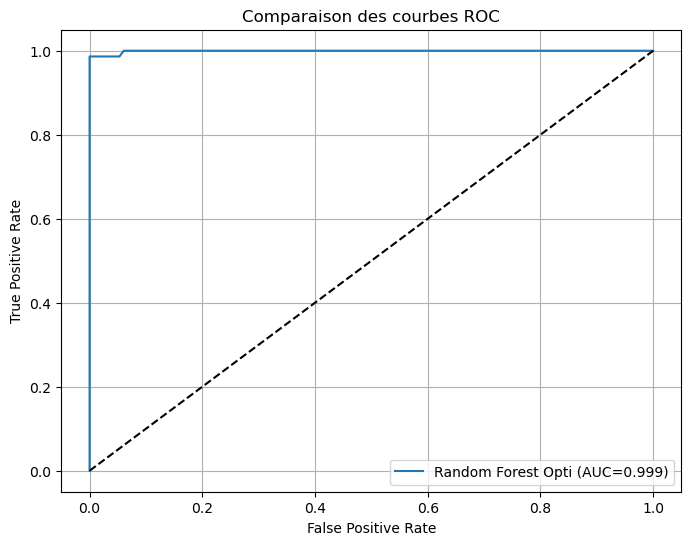

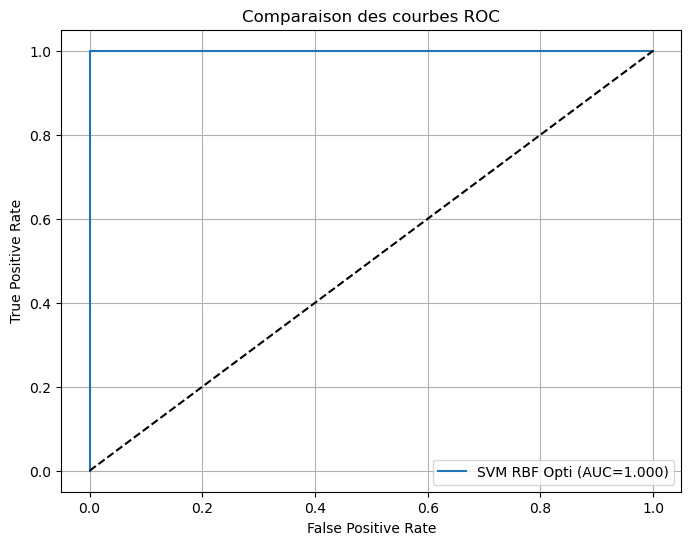

In [144]:
#Comparaison avec courbe Roc des optimisation
afficher_roc({"Random Forest Opti": best_rf}, X_test_fs, y_test)
afficher_roc({"SVM RBF Opti": best_svm}, X_test_fs_norm, y_test)

#### 4.3 Analyse résultats
On a réussi à atteindre 95.1 % d'accuracy avec Random Forest Optimisé, une très belle amélioration qui conserve aussi le Recall à 1.

De plus, même si l'optimisation de SVM RBF n'a pas suffit à rattraper Random Forest, son accuracy a augmenter jusqu'à 90.7%.

Les résultats montrent bien que l'optimisation des hyperparamètres permet d'augmenter significativement les performances des modèles. Et dans notre cas, le modèle Random Forest optimisé retenu pour solution finale est devenu très fiable.

## **Conclusion**

L'objectif du projet était de prédire si la condition d'une valve hydraulique est optimale ou non à partir de mesures de débit et de pression enregistrées sur plusieurs cycles de fonctionnement.

Après une phase de prétraitement et de construction de caractéristiques statistiques, plusieurs algorithmes de classification ont été comparés. Les résultats montrent que les modèles non linéaires sont globalement plus performants que les modèles linéaires sur ce problème.

L'optimisation des hyperparamètres à l'aide de Grid Search et de la validation croisée a permis d'améliorer sensiblement les performances des meilleurs modèles. Le modèle Random Forest optimisé obtient les meilleurs résultats avec une accuracy de 95,1 % et un recall de 100 %, ce qui en fait le modèle retenu pour la prédiction de l'état de la valve.
